# Equilibrium of a Rigid Body in a Harsh Environment, on a BBC micro:bit

**Colin Casey, 2026.** Libraries: `dgs/rigid_body_core.py` (pure Python, no NumPy) and `dgs/rigid_body_harsh.py` (tests: `tests/test_rigid_body_harsh.py`). micro:bit program: `projects/microbit_statics/main.py`. Reference solver: `dgs/free_body_diagram.py`.

## In plain words

A light sensor sits on top of a 3 m pole. The pole is pinned at its base and held by one guy cable anchored 2 m upwind. **Equilibrium of a rigid body** says the pole neither moves nor spins:
$$\sum F_x=0,\qquad \sum F_y=0,\qquad \sum M_A=0 .$$
Three equations, three unknowns: the pin forces $A_x$, $A_y$ and the cable tension $T$.

**Harsh environment:** storm wind pushes on the head and the pole (drag $\tfrac12\rho C_dAv^2$), and glaze ice adds weight *and* widens everything so the wind pushes harder. **Matter and light:** the loads are organized by origin. Weight and drag come from matter; radiation pressure $I/c$ comes from light, and the numbers show where light ranks.

**"Regressed":** two regressions. Cable tension against wind speed is *exactly* $T_0+cv^2$, and least squares recovers $c$. Run time against the number of solves is a straight line whose slope is the **cost per solve**; dividing by the counted arithmetic operations gives the **cost per operation**.

**"BBC python":** the solver uses only lists and floats, so the *identical* code runs on a BBC micro:bit in MicroPython. A test checks that the copy matches byte for byte.

| § | What |
|---|---|
| 1 | Fig. 1: free body diagram of the storm-and-ice case |
| 2 | SymPy: equilibrium equations solved symbolically |
| 3 | Load scenarios, matter vs light, cable safety factor |
| 4 | Fig. 2: tension vs wind (regression) and vs anchor distance |
| 5 | Fig. 3: measured cost per operation: pure Python vs NumPy; micro:bit program |
| 6 | Harsh-environment Python checklist |

Kernel: **py312**.

In [1]:
import pathlib, importlib.util
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import rigid_body_core as core
from dgs import rigid_body_harsh as r
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
M = r.MAST
pd.DataFrame([M]).T.rename(columns={0: 'value'})

,value
H,3.00
d,2.00
pole_D,0.06
pole_mass,12.00
cd_pole,1.20
head_mass,6.00
head_area,0.04
head_surface,0.25
cd_head,1.10


## 1. Figure 1: free body diagram, storm (35 m/s) with 25 mm of glaze ice

The pole is a two-force-free rigid body with a **pin** at A (two unknown components) and a **cable** (one unknown magnitude along a known direction). The loads are the weights of the pole (at mid-height) and of the iced head (at the top), and the wind drag on the pole (resultant at mid-height) and on the head.

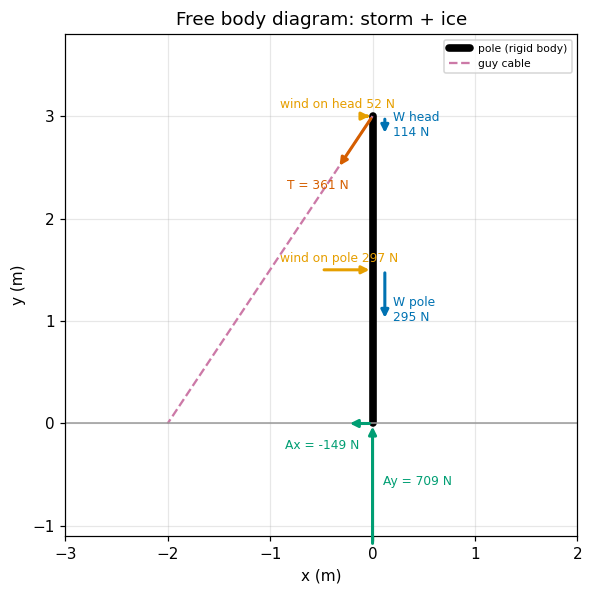

Figure 1. The pole (thick black) pinned at A = (0, 0) with the guy cable (dashed purple) to the upwind anchor at (-2, 0). Blue arrows are weights (pole + ice at mid-height, head + ice at the top), orange arrows wind drag (wind blows in +x), green arrows the pin reactions, the red arrow the cable tension along the cable. Arrow lengths are to scale. Reactions for 35 m/s with 25 mm ice: Ax = -148.6 N, Ay = 708.8 N, T = 360.8 N.


In [2]:
v_s, t_s = 35.0, 0.025
loads = r.mast_loads(v_s, t_s)
Ax, Ay, T = r.solve_mast(v_s, t_s)
H, d = M['H'], M['d']; L = np.hypot(d, H)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 0], [0, H], '-', color=OI['black'], lw=5, solid_capstyle='round', label='pole (rigid body)')
ax.plot([0, -d], [H, 0], '--', color=OI['purple'], lw=1.5, label='guy cable')
ax.plot([-3, 2], [0, 0], '-', color='0.6', lw=1)
sc = 1.2/max(abs(Ay), 1)
def arrow(x, y, fx, fy, c, txt, dx=0.08, dy=0.0):
    ax.annotate('', xy=(x + fx*sc, y + fy*sc), xytext=(x, y), arrowprops=dict(arrowstyle='-|>', color=c, lw=2))
    ax.text(x + fx*sc + dx, y + fy*sc + dy, txt, color=c, fontsize=8)
names = ['W pole', 'W head', 'wind on pole', 'wind on head']
cols = [OI['blue'], OI['blue'], OI['orange'], OI['orange']]
for (Fx, Fy, x, y), nm, c in zip(loads, names, cols):
    if Fx == 0:
        arrow(x + 0.12, y, Fx, Fy, c, f'{nm}\n{abs(Fy):.0f} N')
    else:
        arrow(x - Fx*sc, y, Fx, Fy, c, f'{nm} {Fx:.0f} N', dx=-0.9, dy=0.08)
arrow(0, 0, Ax, 0, OI['green'], f'Ax = {Ax:.0f} N', dx=-0.6, dy=-0.25)
arrow(0, -Ay*sc, 0, Ay, OI['green'], f'Ay = {Ay:.0f} N', dx=0.1, dy=-0.6)
arrow(0, H, -T*d/L, -T*H/L, OI['red'], f'T = {T:.0f} N', dx=-0.5, dy=-0.2)
ax.set(xlim=(-3, 2), ylim=(-1.1, 3.8), aspect='equal', xlabel='x (m)', ylabel='y (m)', title='Free body diagram: storm + ice')
ax.legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()
print('Figure 1. The pole (thick black) pinned at A = (0, 0) with the guy cable (dashed purple) to the upwind anchor at (-2, 0). '
      'Blue arrows are weights (pole + ice at mid-height, head + ice at the top), orange arrows wind drag (wind blows in +x), '
      'green arrows the pin reactions, the red arrow the cable tension along the cable. Arrow lengths are to scale. '
      f'Reactions for 35 m/s with 25 mm ice: Ax = {Ax:.1f} N, Ay = {Ay:.1f} N, T = {T:.1f} N.')

## 2. The equilibrium equations, solved symbolically

Taking moments about A removes $A_x$ and $A_y$, so $T$ follows from one equation. The cable acts at the top with direction $(-d,-H)/L$, $L=\sqrt{d^2+H^2}$:

In [3]:
Axs, Ays, Ts, Hs, ds, Wp, Wh, Fp, Fh = sp.symbols('A_x A_y T H d W_p W_h F_p F_h', real=True)
Ls = sp.sqrt(ds**2 + Hs**2)
eqs = [sp.Eq(Axs + Fp + Fh - Ts*ds/Ls, 0),                          # sum Fx
       sp.Eq(Ays - Wp - Wh - Ts*Hs/Ls, 0),                          # sum Fy
       sp.Eq(-(Fp*Hs/2 + Fh*Hs) + Ts*ds*Hs/Ls, 0)]                  # sum M_A (counterclockwise +)
sol = sp.solve(eqs, [Axs, Ays, Ts], dict=True)[0]
for k_ in (Ts, Axs, Ays):
    display(Math(sp.latex(k_) + ' = ' + sp.latex(sp.simplify(sol[k_]))))
num = {Hs: H, ds: d, Wp: -loads[0][1], Wh: -loads[1][1], Fp: loads[2][0], Fh: loads[3][0]}
print('symbolic -> numeric:', [round(float(sol[k_].subs(num)), 3) for k_ in (Axs, Ays, Ts)],
      '| pure-Python core:', [round(x_, 3) for x_ in (Ax, Ay, T)])
print('Reading T: wind moment about the base divided by the cable\'s lever arm d H / L. A farther anchor (bigger d) gives a longer arm.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

symbolic -> numeric: [-148.562, 708.804, 360.818] | pure-Python core: [-148.562, 708.804, 360.818]
Reading T: wind moment about the base divided by the cable's lever arm d H / L. A farther anchor (bigger d) gives a longer arm.


## 3. Load scenarios: matter vs light, and the cable's margin

The cable is assumed to be a 6 mm galvanized steel wire rope with a minimum breaking load of about **20 kN** (a typical catalog order of magnitude; check the real part). Every row is solved two independent ways, the pure-Python core and `dgs.free_body_diagram` (NumPy), and checked by summing all forces and moments back to zero.

In [4]:
MBL = 20e3
scen = [('calm', 0, 0, 0), ('noon sun only (1000 W/m^2)', 0, 0, 1000), ('breeze 10 m/s', 10, 0, 0),
        ('storm 35 m/s', 35, 0, 0), ('storm 35 m/s + 25 mm ice', 35, 0.025, 0), ('extreme 50 m/s + 25 mm ice', 50, 0.025, 0)]
rows = []
for name, v_, ti, I_ in scen:
    a_ = r.solve_mast(v_, ti, I_)
    b_ = r.solve_mast_numpy(v_, ti, I_)
    rows.append(dict(scenario=name, Ax_N=a_[0], Ay_N=a_[1], T_N=a_[2], max_diff_vs_numpy=float(np.max(np.abs(np.array(a_) - b_))),
                     equilibrium_residual=r.equilibrium_residual(v_, ti, I_),
                     cable_safety_factor=(MBL/a_[2] if a_[2] > 1e-9 else np.inf)))
display(pd.DataFrame(rows).round(6))
ld = r.mast_loads(35, 0.025, 1000)
org = pd.DataFrame([dict(load='weight: pole + ice', origin='matter (gravity)', N=-ld[0][1]),
                    dict(load='weight: head + ice', origin='matter (gravity)', N=-ld[1][1]),
                    dict(load='drag: pole (35 m/s, iced)', origin='matter (air momentum)', N=ld[2][0]),
                    dict(load='drag: head (35 m/s, iced)', origin='matter (air momentum)', N=r.drag(35, (np.sqrt(M['head_area']) + 0.05)**2, M['cd_head'])),
                    dict(load='radiation pressure on head (1000 W/m^2)', origin='light (photon momentum)', N=r.radiation_force(1000, M['head_area']))])
org['fraction_of_largest'] = org.N/org.N.max()
print('Loads organized by origin, storm + ice + full sun:')
org

,scenario,Ax_N,Ay_N,T_N,max_diff_vs_numpy,equilibrium_residual,cable_safety_factor
0,calm,0.000000,176.580000,0.000000,0.0,0.0,inf
1,noon sun only (1000 W/m^2),0.000000,176.580000,0.000000,0.0,0.0,8.314747e+10
2,breeze 10 m/s,-6.615000,190.545000,16.783841,0.0,0.0,1.191622e+03
3,storm 35 m/s,-81.033750,347.651250,205.602055,0.0,0.0,9.727529e+01
4,storm 35 m/s + 25 mm ice,-148.561875,708.804189,360.818079,0.0,0.0,5.542959e+01
5,extreme 50 m/s + 25 mm ice,-303.187500,1021.276806,736.363427,0.0,0.0,2.716050e+01


Loads organized by origin, storm + ice + full sun:


,load,origin,N,fraction_of_largest
0,weight: pole + ice,matter (gravity),2.945441e+02,9.913181e-01
1,weight: head + ice,matter (gravity),1.140413e+02,3.838173e-01
2,"drag: pole (35 m/s, iced)",matter (air momentum),2.971238e+02,1.000000e+00
3,"drag: head (35 m/s, iced)",matter (air momentum),5.158398e+01,1.736111e-01
4,radiation pressure on head (1000 W/m^2),light (photon momentum),1.334256e-07,4.490575e-10


## 4. Figure 2: regressing tension on wind speed, and choosing the anchor

Equilibrium is linear in the loads and drag is quadratic in $v$, so $T(v)=T_0+c\,v^2$ exactly ($T_0=0$ here, because weight alone needs no cable). A least-squares fit to simulated $(v,T)$ pairs recovers $c$, which is how you would calibrate from field data. Ice raises $c$ because it widens the pole and head.

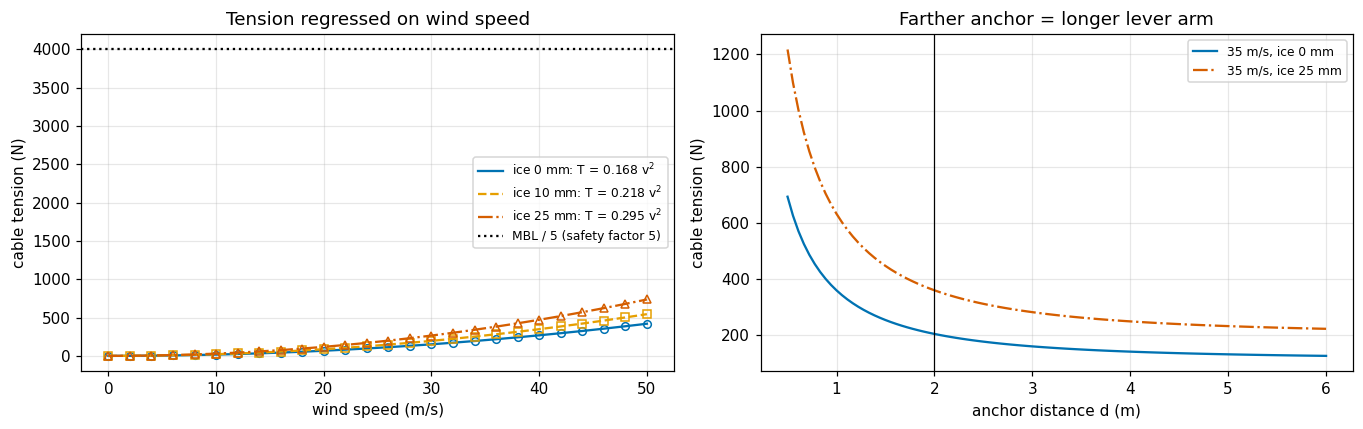

Figure 2. Left: cable tension against wind speed (markers: equilibrium solves) with the least-squares fits T0 + c v^2 (lines) for no ice (blue, solid), 10 mm (orange, dashed) and 25 mm (red, dash-dot); every fit has R^2 = 1 and T0 = 0. The dotted line is one fifth of the assumed 20 kN breaking load. Right: tension at 35 m/s against anchor distance; it falls as L/(d H) shrinks, steeply below d ~ 1 m (the thin line marks the design d = 2 m).


,ice_mm,fitted_c_N_per_mps2,T0_N,r2
0,0.0,0.167838,5.768439e-14,1.0
1,10.0,0.217792,1.289474e-13,1.0
2,25.0,0.294545,8.393027e-14,1.0


In [5]:
vs = np.linspace(0, 50, 26)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
fit_rows = []
for ti, c_, ls, mk in [(0.0, OI['blue'], '-', 'o'), (0.010, OI['orange'], '--', 's'), (0.025, OI['red'], '-.', '^')]:
    Tv = np.array([r.solve_mast(v_, ti)[2] for v_ in vs])
    T0, cc, r2 = r.regress_quadratic(vs, Tv)
    ax[0].plot(vs, Tv, mk, mfc='none', color=c_, ms=5)
    ax[0].plot(vs, T0 + cc*vs**2, ls, color=c_, label=f'ice {ti*1e3:.0f} mm: T = {cc:.3f} v$^2$')
    fit_rows.append(dict(ice_mm=ti*1e3, fitted_c_N_per_mps2=cc, T0_N=T0, r2=r2))
ax[0].axhline(MBL/5, color=OI['black'], ls=':', label='MBL / 5 (safety factor 5)')
ax[0].set(xlabel='wind speed (m/s)', ylabel='cable tension (N)', title='Tension regressed on wind speed'); ax[0].legend(fontsize=8)
dd = np.linspace(0.5, 6, 100)
for ti, c_, ls in [(0.0, OI['blue'], '-'), (0.025, OI['red'], '-.')]:
    mast2 = dict(M)
    Td = []
    for d_ in dd:
        mast2['d'] = d_
        Td.append(r.solve_mast(35, ti, 0, mast2)[2])
    ax[1].plot(dd, Td, ls, color=c_, label=f'35 m/s, ice {ti*1e3:.0f} mm')
ax[1].axvline(M['d'], color=OI['black'], lw=0.8)
ax[1].set(xlabel='anchor distance d (m)', ylabel='cable tension (N)', title='Farther anchor = longer lever arm'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 2. Left: cable tension against wind speed (markers: equilibrium solves) with the least-squares fits T0 + c v^2 '
      '(lines) for no ice (blue, solid), 10 mm (orange, dashed) and 25 mm (red, dash-dot); every fit has R^2 = 1 and T0 = 0. '
      'The dotted line is one fifth of the assumed 20 kN breaking load. Right: tension at 35 m/s against anchor distance; it '
      'falls as L/(d H) shrinks, steeply below d ~ 1 m (the thin line marks the design d = 2 m).')
pd.DataFrame(fit_rows)

## 5. Figure 3: cost per operation, measured and regressed

Time $N$ solves for several $N$, then fit $t=t_0+sN$. The slope $s$ is the cost per solve, and the intercept $t_0$ absorbs fixed overhead. The pure-Python solver counts its own arithmetic (61 additions, subtractions, multiplications and divisions per mast solve), so $s/61$ is the cost per operation, *including* the interpreter's bookkeeping around each one. The timings come from **this PC** and change with load and hardware.

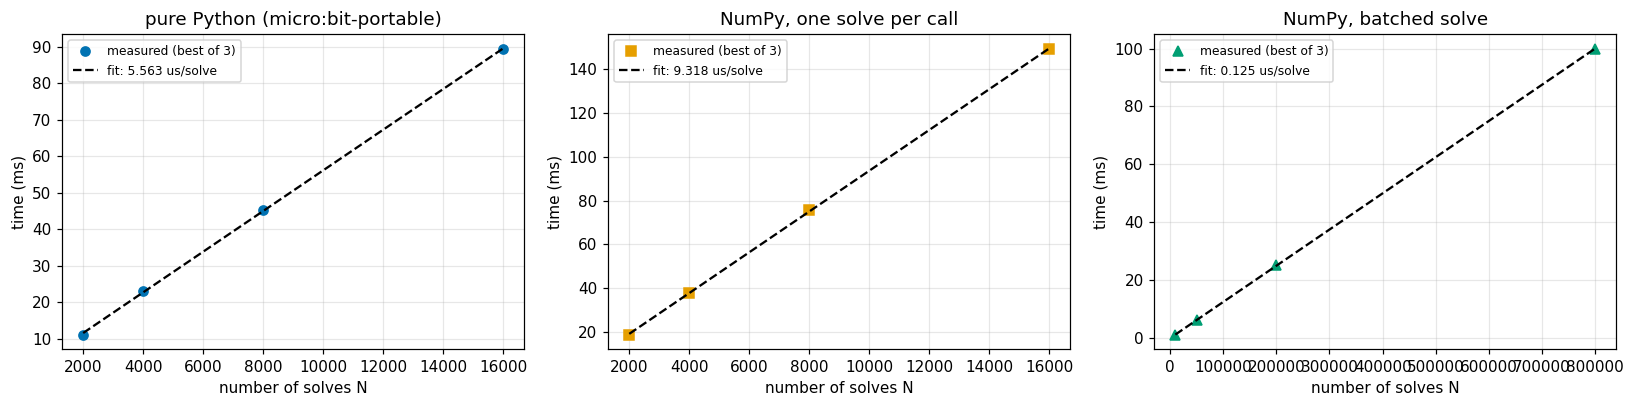

Figure 3. Wall time against number of solves for each implementation (markers) with the regression line (dashed black). All three are straight lines (R^2 in the table); the slopes are the cost per solve.
pure Python vs NumPy one-at-a-time: 1.67x (pure Python wins: NumPy call overhead dominates a 3x3); batched NumPy is 45x faster than pure Python per solve.
Energy per operation = (power drawn) x (time per op); measure the power (e.g. a USB power meter on the micro:bit) rather than assuming it.


,implementation,us_per_solve,ns_per_op,overhead_s,r2,ops_per_solve
0,pure Python (micro:bit-portable),5.563465,91.204341,0.000461,0.999836,61
1,"NumPy, one solve per call",9.318102,152.755766,0.000509,0.999891,61
2,"NumPy, batched solve",0.124906,2.047637,0.000084,0.999985,61


In [6]:
res = r.cost_per_operation()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a_, row, c_, mk in zip(ax, res, [OI['blue'], OI['orange'], OI['green']], ['o', 's', '^']):
    N_ = np.array(row['Ns']); t_ = np.array(row['times_s'])
    a_.plot(N_, t_*1e3, mk, color=c_, label='measured (best of 3)')
    a_.plot(N_, (row['overhead_s'] + row['s_per_solve']*N_)*1e3, '--', color=OI['black'], label=f"fit: {row['s_per_solve']*1e6:.3f} us/solve")
    a_.set(xlabel='number of solves N', ylabel='time (ms)', title=row['implementation']); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 3. Wall time against number of solves for each implementation (markers) with the regression line (dashed black). '
      'All three are straight lines (R^2 in the table); the slopes are the cost per solve.')
tab = pd.DataFrame([{k: row[k] for k in ('implementation', 's_per_solve', 's_per_op', 'overhead_s', 'r2', 'ops_per_solve')} for row in res])
tab['us_per_solve'] = tab.s_per_solve*1e6; tab['ns_per_op'] = tab.s_per_op*1e9
fast = tab.loc[tab.us_per_solve.idxmin(), 'implementation']
print(f"pure Python vs NumPy one-at-a-time: {tab.us_per_solve[1]/tab.us_per_solve[0]:.2f}x "
      f"({'pure Python wins: NumPy call overhead dominates a 3x3' if tab.us_per_solve[0] < tab.us_per_solve[1] else 'NumPy wins'}); "
      f"batched NumPy is {tab.us_per_solve[0]/tab.us_per_solve[2]:.0f}x faster than pure Python per solve.")
print('Energy per operation = (power drawn) x (time per op); measure the power (e.g. a USB power meter on the micro:bit) rather than assuming it.')
tab[['implementation', 'us_per_solve', 'ns_per_op', 'overhead_s', 'r2', 'ops_per_solve']]

### The micro:bit program

`projects/microbit_statics/main.py` contains the shared solver block, a pure-Python copy of the load model, timing with `utime.ticks_us`, and the same least-squares line fit, done **on the device**. To use it:

1. Open python.microbit.org (or run `uflash main.py`) and flash the file to a micro:bit V2.
2. Open the serial console and press **A**.
3. Read `us_per_solve` and `us_per_op`. The display also scrolls $T$ and µs/op.

I haven't run it on micro:bit hardware, so the microcontroller numbers are yours to measure. Below, the *same file* runs on CPython to show that the logic and the answer agree.

In [7]:
main = pathlib.Path.cwd().parent / 'projects' / 'microbit_statics' / 'main.py'
txt = main.read_text(encoding='utf-8')
blk = lambda s_: s_[s_.index('# --- BEGIN SHARED CORE'):s_.index('# --- END SHARED CORE ---')]
same = blk(txt) == blk((pathlib.Path.cwd().parent / 'dgs' / 'rigid_body_core.py').read_text(encoding='utf-8'))
print(f'main.py: {len(txt.splitlines())} lines; solver block identical to dgs/rigid_body_core.py: {same}')
spec = importlib.util.spec_from_file_location('microbit_main', main)
mb = importlib.util.module_from_spec(spec); spec.loader.exec_module(mb)
T_mb, us_op = mb.run(Ns=(2000, 4000, 8000, 16000))
print(f'CPython run of the micro:bit file: T = {T_mb:.1f} N (dgs: {r.solve_mast(35, 0.025)[2]:.1f} N), {us_op*1e3:.0f} ns/op on this PC')

main.py: 164 lines; solver block identical to dgs/rigid_body_core.py: True
storm 35 m/s + 25 mm ice: Ax=-148.6 N  Ay=708.8 N  T=360.8 N
N=2000  time_us=16533
N=4000  time_us=22677
N=8000  time_us=46178
N=16000  time_us=91387
overhead_us=3134.3  us_per_solve=5.47  ops_per_solve=61  us_per_op=0.090
CPython run of the micro:bit file: T = 360.8 N (dgs: 360.8 N), 90 ns/op on this PC


## 6. Harsh-environment Python: checklist used here

| risk in the field | what the code does |
|---|---|
| a sensor returns NaN/inf (icing, a cut cable) | `solve3` rejects non-finite input instead of propagating garbage |
| a support fails (geometry becomes a mechanism) | pivot below 1e-12 raises "singular", not a silent huge answer |
| a cable can only pull | the wind case is set up with the cable upwind, so $T\ge0$; a negative $T$ would flag a wrong load path |
| no NumPy / little RAM on a microcontroller | the core uses fixed-size lists and no allocation inside the elimination |
| code drift between PC and device | one shared block, plus a test that the device copy is byte-identical |
| timing jitter | best-of-3 timing and regression over several N, so overhead lands in the intercept |

**References** (from memory; verify before citing)
[1] R. C. Hibbeler, *Engineering Mechanics: Statics*, 14th ed. Hoboken, NJ, USA: Pearson, 2016, ch. 5 ("Equilibrium of a Rigid Body").
[2] ASCE/SEI 7-22, *Minimum Design Loads and Associated Criteria for Buildings and Other Structures*. Reston, VA, USA: ASCE, 2022 (wind and atmospheric ice loads).
[3] ISO 12494:2017, *Atmospheric icing of structures*. Geneva, Switzerland: ISO, 2017.
[4] Micro:bit Educational Foundation, "MicroPython for the BBC micro:bit," documentation, microbit-micropython.readthedocs.io.

**Limitations.**
- Planar model with the wind in the plane of the cable. A real mast needs at least three guys for wind from any direction.
- The pole's distributed loads are replaced by their resultants.
- Drag coefficients, ice density and the cable strength are typical assumed values, not design values.
- Pole buckling and bending stress are not checked.
- The micro:bit has not been run, and the PC timings are machine-dependent.